In [41]:
import matplotlib
import numpy as np
import pandas as pd
from narwhals import Int64
import seaborn as sns
from scipy.special.cython_special import stdtrit
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import make_scorer, brier_score_loss
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
import matplotlib.pyplot as plt
from sklearn.base import clone
from scipy import special

In [3]:
train_df = pd.read_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\cleaned_data\stop_search_test1.csv", index_col=0)

# Preprocessing before pipeline and modeling
## We drop unnecessary columns, define categorical and discrete/numerical columns for imputation, and convert categorical variables into strings

In [4]:
# Dropping unnecessary columns for modeling
train_date = train_df["event_dt"]
train_df = train_df.drop(["event_dt", "orig_age", "vital_flag", "orig_height", "orig_weight", "BMI", "year", "Zone", "Latitude", "Longitude", "SubjectID"], axis = 1)

# Unfloating zip code
train_df["Zip"] = train_df["Zip"].astype("Int64")

# Defining categorical columns
cat_cols = ["SubjectRace", "Zip", "District"]
# Defining discrete/numerical columns
dis_cols = ["SubjectGender", "SubjectAge", "SubjectHeight", "SubjectWeight", "isLA","VehicleYear", "SubjectHasPhotoID", "hour", "night", "isDriver"]
# Numerical columns we would like to scale
scale_cols = ["SubjectAge", "SubjectHeight", "SubjectWeight", "VehicleYear", "hour"]
# Binary columns
bin_cols = ["SubjectGender", "isLA", "SubjectHasPhotoID", "night", "isDriver"]

# Converting variables into strings
train_df[cat_cols] = train_df[cat_cols].astype(str)

In [5]:
target = "search_occurred"
X_train = train_df.drop([target], axis = 1)[cat_cols + dis_cols]
y_train = train_df[target]

# Defining classes to build pipeline
## CatBinner groups sparse labels in categorical variables in an Other category. RoundImputed is used after imputation, to ensure imputed numerical values are discrete

In [6]:
class CatBinner(BaseEstimator, TransformerMixin):
    def __init__(self, cols, min_freq=0.01, fill_value="Other"):
        self.cols = cols
        self.min_freq = min_freq
        self.fill_value = fill_value

    def fit(self, X, y=None):
        self.keep_labels = {}
        for c in self.cols:
            freq = X[c].value_counts(normalize=True)
            self.keep_labels[c] = freq[freq >= self.min_freq].index.tolist()

        return self

    def transform(self, X):
        X_copy = X.copy()
        for c in self.cols:
            labels = self.keep_labels[c]
            X_copy[c] = np.where(X_copy[c].isin(labels) | X_copy[c].isna(), X_copy[c], self.fill_value)
        return X_copy

    def set_output(self, *, transform=None):
        return self

class RoundImputed(BaseEstimator, TransformerMixin):
    def __init__(self, cols):
        self.cols = cols

    def fit(self, X, y=None):
        rounded = X[self.cols].round()
        self.min_ = rounded.min()
        self.max_ = rounded.max()
        return self

    def transform(self, X):
        X_copy = X.copy()
        X_copy[self.cols] = X_copy[self.cols].round().clip(self.min_, self.max_, axis=1)
        return X_copy

    def set_output(self, *, transform=None):
        return self

class OrdEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols, inner):
        self.cat_cols = cat_cols
        self.inner = inner

    def _encode(self, X):
        X_enc = X.copy()
        X_enc[self.cat_cols] = self.encoder_.transform(X[self.cat_cols])
        return X_enc

    def _decode(self, X_imp):
        X_dec = X_imp.copy()
        X_dec[self.cat_cols] = self.encoder_.inverse_transform(X_imp[self.cat_cols])
        return X_dec

    def fit_transform(self, X, y=None):
        self.encoder_ = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)
        self.encoder_.fit(X[self.cat_cols])
        self.inner_ = clone(self.inner)
        return self._decode(self.inner_.fit_transform(self._encode(X), y))

    def fit(self, X, y=None):
        self.fit_transform(X, y)
        return self

    def transform(self, X):
        return self._decode(self.inner_.transform(self._encode(X)))

    def set_output(self, *, transform=None):
        return self

# Building pipeline
## Define a function to construct pipeline given model, and discrete and categorical columns

In [7]:
def build_pipeline(model, cat_cols, dis_cols, scale_cols):
    imputer = IterativeImputer(estimator=HistGradientBoostingRegressor(max_iter=50, random_state=10), skip_complete=True, max_iter=5, tol=1e-2, random_state=10)

    impute = Pipeline([
        ("imputer", imputer),
        ("round", RoundImputed(cols=cat_cols + dis_cols)),
    ])

    impute.set_output(transform="pandas")

    encode = ColumnTransformer([("encode", OneHotEncoder(handle_unknown="ignore"), cat_cols), ("scale", StandardScaler(), scale_cols)], remainder="passthrough", verbose_feature_names_out=False)

    pipeline = Pipeline([
        ("bin", CatBinner(cols=cat_cols, min_freq=0.01, fill_value="Other")),
        ("imputer", OrdEncoder(cat_cols, impute)),
        ("encode", encode),
        ("model", model)
    ], memory="cache_dir")

    return pipeline

## Defining ECE scorer

In [11]:
def expected_calibration_error(y_true, y_prob, n_bins=20):
    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    ece = 0.0
    for i in range(n_bins):
        bin_mask = (y_prob >= bin_edges[i]) & (y_prob <= bin_edges[i + 1])
        if np.any(bin_mask):
            bin_accuracy = np.mean(y_true[bin_mask])
            bin_confidence = bin_centers[i]
            ece += np.abs(bin_confidence - bin_accuracy) * np.sum(bin_mask)
    ece /= y_true.size
    return ece

ece = make_scorer(expected_calibration_error, greater_is_better=False, response_method="predict_proba", n_bins = 20)

# Modeling
## Logistic regression

In [13]:
lr = LogisticRegression(l1_ratio=1, C = 0.012742749857031334, max_iter = 1000, random_state=10, solver="saga")

pipeline = build_pipeline(lr, cat_cols, dis_cols, scale_cols)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=10)

lr_cross_val_scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring={"average_precision":"average_precision", "roc_auc":"roc_auc", "neg_brier_score":"neg_brier_score", "neg_ece":ece}, return_train_score=True, error_score="raise", verbose=2)

[CV] END .................................................... total time=   0.3s
[CV] END .................................................... total time=   0.3s
[CV] END .................................................... total time=   0.3s
[CV] END .................................................... total time=   0.4s
[CV] END .................................................... total time=   0.3s
[CV] END .................................................... total time=   0.3s
[CV] END .................................................... total time=   0.3s
[CV] END .................................................... total time=   0.3s
[CV] END .................................................... total time=   0.4s
[CV] END .................................................... total time=   0.3s


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:    8.2s finished


## Decision Tree

In [14]:
dt = DecisionTreeClassifier(criterion = "entropy", max_depth = 9, min_samples_leaf = 31, min_samples_split = 29, random_state=10)

pipeline = build_pipeline(dt, cat_cols, dis_cols, scale_cols)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=10)

dt_cross_val_scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring={"average_precision":"average_precision", "roc_auc":"roc_auc", "neg_brier_score":"neg_brier_score", "neg_ece":ece}, return_train_score=True, error_score="raise", verbose=2)

[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:    5.0s finished


## Random Forest

In [15]:
rf = RandomForestClassifier(criterion="gini", max_depth=None, min_samples_split=13, min_samples_leaf=11, max_features="log2", random_state=10)

pipeline = build_pipeline(rf, cat_cols, dis_cols, scale_cols)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=10)

rf_cross_val_scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring={"average_precision":"average_precision", "roc_auc":"roc_auc", "neg_brier_score":"neg_brier_score", "neg_ece":ece}, return_train_score=True, error_score="raise", verbose=2)

[CV] END .................................................... total time=   1.2s
[CV] END .................................................... total time=   1.2s
[CV] END .................................................... total time=   1.1s
[CV] END .................................................... total time=   1.2s
[CV] END .................................................... total time=   1.2s
[CV] END .................................................... total time=   1.1s
[CV] END .................................................... total time=   1.2s
[CV] END .................................................... total time=   1.2s
[CV] END .................................................... total time=   1.2s
[CV] END .................................................... total time=   1.2s


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:   16.9s finished


# Evaluating metrics

In [34]:
# Saving results
lr_scores = pd.DataFrame(lr_cross_val_scores)
dt_scores = pd.DataFrame(dt_cross_val_scores)
rf_scores = pd.DataFrame(rf_cross_val_scores)

# Making brier and ece nonnegative
lr_scores["test_brier_score"], lr_scores["train_brier_score"], lr_scores["test_ece"], lr_scores["train_ece"] = -lr_scores["test_neg_brier_score"], -lr_scores["train_neg_brier_score"], -lr_scores["test_neg_ece"], -lr_scores["train_neg_ece"]

dt_scores["test_brier_score"], dt_scores["train_brier_score"], dt_scores["test_ece"], dt_scores["train_ece"] = -dt_scores["test_neg_brier_score"], -dt_scores["train_neg_brier_score"], -dt_scores["test_neg_ece"], -dt_scores["train_neg_ece"]

rf_scores["test_brier_score"], rf_scores["train_brier_score"], rf_scores["test_ece"], rf_scores["train_ece"] = -rf_scores["test_neg_brier_score"], -rf_scores["train_neg_brier_score"], -rf_scores["test_neg_ece"], -rf_scores["train_neg_ece"]

# Creating standard deviation and error columns
t_alpha = special.stdtrit(len(lr_scores)-1, 0.975)
summary_lr = (lr_scores.agg(["mean", "std"]).T.reset_index())
summary_lr.columns = ["metric", "lr_mean", "lr_std"]
summary_lr["lr_se"] = summary_lr["lr_std"]/np.sqrt(len(lr_scores))
summary_lr["lr_lower_95_ci"] = summary_lr["lr_mean"] - t_alpha*summary_lr["lr_se"]
summary_lr["lr_upper_95_ci"] = summary_lr["lr_mean"] + t_alpha*summary_lr["lr_se"]

summary_dt = (dt_scores.agg(["mean", "std"]).T.reset_index())
summary_dt.columns = ["metric", "dt_mean", "dt_std"]
summary_dt["dt_se"] = summary_dt["dt_std"]/np.sqrt(len(dt_scores))
summary_dt["dt_lower_95_ci"] = summary_dt["dt_mean"] - t_alpha*summary_dt["dt_se"]
summary_dt["dt_upper_95_ci"] = summary_dt["dt_mean"] + t_alpha*summary_dt["dt_se"]

summary_rf = (rf_scores.agg(["mean", "std"]).T.reset_index())
summary_rf.columns = ["metric", "rf_mean", "rf_std"]
summary_rf["rf_se"] = summary_rf["rf_std"]/np.sqrt(len(rf_scores))
summary_rf["rf_lower_95_ci"] = summary_rf["rf_mean"] - t_alpha*summary_rf["rf_se"]
summary_rf["rf_upper_95_ci"] = summary_rf["rf_mean"] + t_alpha*summary_rf["rf_se"]

In [39]:
# Combining results into dataframe
score_summary = pd.concat([summary_lr, summary_dt, summary_rf], axis=1)
# Drop duplicate metric columns
score_summary = score_summary.T.drop_duplicates().T
score_summary

,metric,lr_mean,lr_std,lr_se,lr_lower_95_ci,lr_upper_95_ci,dt_mean,dt_std,dt_se,dt_lower_95_ci,dt_upper_95_ci,rf_mean,rf_std,rf_se,rf_lower_95_ci,rf_upper_95_ci
0,fit_time,0.297373,0.027196,0.0086,0.277918,0.316828,0.215716,0.02284,0.007223,0.199377,0.232055,1.179639,0.033357,0.010549,1.155776,1.203501
1,score_time,0.126666,0.012227,0.003867,0.117919,0.135413,0.071302,0.006125,0.001937,0.066921,0.075684,0.104738,0.0075,0.002372,0.099373,0.110103
2,test_average_precision,0.126603,0.01793,0.00567,0.113777,0.139429,0.134917,0.017123,0.005415,0.122668,0.147166,0.172508,0.024424,0.007723,0.155037,0.18998
3,train_average_precision,0.124354,0.002725,0.000862,0.122405,0.126304,0.207236,0.004755,0.001504,0.203834,0.210638,0.436226,0.006557,0.002074,0.431535,0.440916
4,test_roc_auc,0.713457,0.027838,0.008803,0.693543,0.733371,0.698605,0.025534,0.008075,0.680339,0.716871,0.752579,0.02761,0.008731,0.732828,0.77233
5,train_roc_auc,0.716985,0.00323,0.001021,0.714675,0.719296,0.807481,0.004635,0.001466,0.804165,0.810797,0.928362,0.001258,0.000398,0.927462,0.929262
6,test_neg_brier_score,-0.050487,0.000331,0.000105,-0.050724,-0.05025,-0.050855,0.000823,0.00026,-0.051443,-0.050266,-0.04928,0.000584,0.000185,-0.049698,-0.048862
7,train_neg_brier_score,-0.05042,0.000067,0.000021,-0.050468,-0.050373,-0.047388,0.000151,0.000048,-0.047496,-0.04728,-0.044456,0.000101,0.000032,-0.044528,-0.044383
8,test_neg_ece,-0.006713,0.003465,0.001096,-0.009192,-0.004234,-0.014312,0.003317,0.001049,-0.016685,-0.011939,-0.008182,0.003155,0.000998,-0.010439,-0.005925
9,train_neg_ece,-0.003909,0.000541,0.000171,-0.004296,-0.003523,-0.007101,0.001397,0.000442,-0.0081,-0.006102,-0.044235,0.000801,0.000253,-0.044808,-0.043661


In [40]:
# Saving results
summary_lr.to_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\modeling_results\lr_cross_val_scores.csv", index=False)
summary_dt.to_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\modeling_results\dt_cross_val_scores.csv", index=False)
summary_rf.to_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\modeling_results\rf_cross_val_scores.csv", index=False)
score_summary.to_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\modeling_results\model_cross_val_scores.csv", index=False)

## Plotting cross validation scores

In [58]:
lr_scores["Model"] = "Logistic Regression"
dt_scores["Model"] = "Decision Tree"
rf_scores["Model"] = "Random Forest"
scores = pd.concat([lr_scores, dt_scores, rf_scores])
scores

,fit_time,score_time,test_average_precision,train_average_precision,test_roc_auc,train_roc_auc,test_neg_brier_score,train_neg_brier_score,test_neg_ece,train_neg_ece,test_brier_score,train_brier_score,test_ece,train_ece,model,Model
0,0.256013,0.122462,0.152229,0.119148,0.759936,0.711657,-0.049900,-0.050537,-0.012669,-0.002950,0.049900,0.050537,0.012669,0.002950,Logistic Regression,Logistic Regression
1,0.282708,0.121000,0.111378,0.128539,0.672140,0.721983,-0.050913,-0.050319,-0.010476,-0.004604,0.050913,0.050319,0.010476,0.004604,Logistic Regression,Logistic Regression
2,0.283070,0.119972,0.123084,0.125313,0.695229,0.719160,-0.050617,-0.050380,-0.010295,-0.004501,0.050617,0.050380,0.010295,0.004501,Logistic Regression,Logistic Regression
3,0.351813,0.136086,0.121634,0.125203,0.730210,0.715402,-0.050394,-0.050439,-0.005795,-0.003791,0.050394,0.050439,0.005795,0.003791,Logistic Regression,Logistic Regression
4,0.294379,0.120051,0.119032,0.126256,0.706054,0.719419,-0.050580,-0.050369,-0.005234,-0.003598,0.050580,0.050369,0.005234,0.003598,Logistic Regression,Logistic Regression
5,0.291702,0.140136,0.112237,0.126201,0.690911,0.718610,-0.050776,-0.050382,-0.003289,-0.004045,0.050776,0.050382,0.003289,0.004045,Logistic Regression,Logistic Regression
6,0.294970,0.109738,0.121654,0.124452,0.707329,0.717558,-0.050570,-0.050414,-0.003701,-0.004263,0.050570,0.050414,0.003701,0.004263,Logistic Regression,Logistic Regression
7,0.300197,0.123340,0.165716,0.120792,0.754484,0.712085,-0.049929,-0.050520,-0.007493,-0.003183,0.049929,0.050520,0.007493,0.003183,Logistic Regression,Logistic Regression
8,0.334103,0.151574,0.124521,0.124187,0.699838,0.717421,-0.050617,-0.050413,-0.002168,-0.003943,0.050617,0.050413,0.002168,0.003943,Logistic Regression,Logistic Regression
9,0.284773,0.122303,0.114546,0.123452,0.718440,0.716558,-0.050574,-0.050429,-0.006009,-0.004214,0.050574,0.050429,0.006009,0.004214,Logistic Regression,Logistic Regression


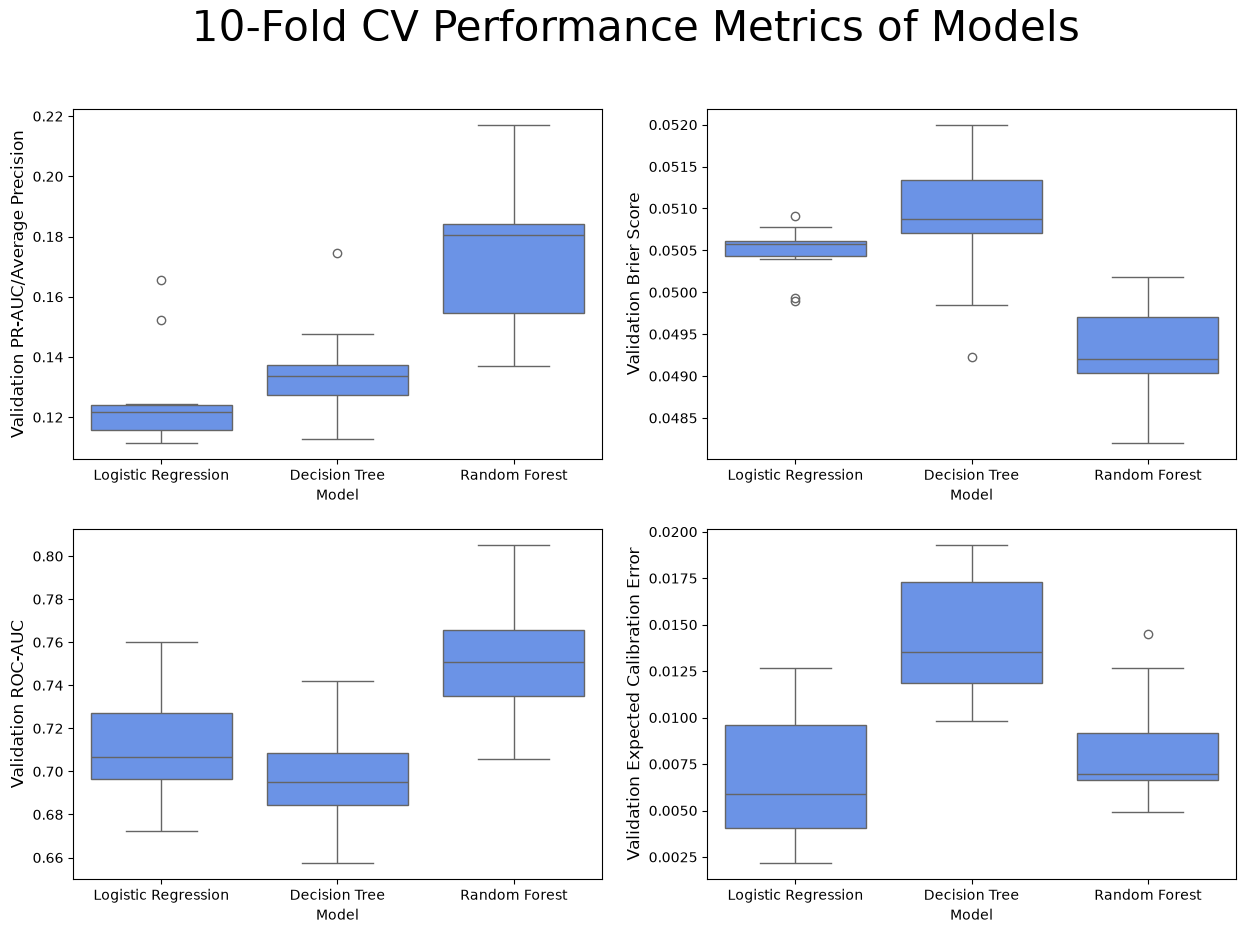

In [73]:
fig, axs = plt.subplots(2,2, figsize=(15,10))

sns.boxplot(scores, x = "Model", y = "test_average_precision", order=["Logistic Regression", "Decision Tree", "Random Forest"], ax = axs[0,0])
axs[0,0].set_ylabel("Validation PR-AUC/Average Precision", fontsize=12)

sns.boxplot(scores, x = "Model", y = "test_brier_score", order=["Logistic Regression", "Decision Tree", "Random Forest"], ax = axs[0,1])
axs[0,1].set_ylabel("Validation Brier Score", fontsize=12)

sns.boxplot(scores, x = "Model", y = "test_roc_auc", order=["Logistic Regression", "Decision Tree", "Random Forest"], ax = axs[1,0])
axs[1,0].set_ylabel("Validation ROC-AUC", fontsize=12)

sns.boxplot(scores, x = "Model", y = "test_ece", order=["Logistic Regression", "Decision Tree", "Random Forest"], ax = axs[1,1])
axs[1,1].set_ylabel("Validation Expected Calibration Error", fontsize=12)

plt.suptitle("10-Fold CV Performance Metrics of Models", fontsize=30)
plt.savefig(r"C:\Users\gelet\PycharmProjects\stop-and-search\plots\cv_models_boxplot.png", bbox_inches="tight")
plt.show()